# Phân tích toàn bộ dữ liệu `chua_co_loc_khi_van_3_c`

Notebook này thực hiện audit từ đầu đến cuối:

1. Tìm và đọc toàn bộ folder ngày/run.
2. Kiểm tra tính đầy đủ, schema, JSON, CSV, PNG và liên kết `run_id`.
3. Tách `session` (folder số) và `collect` (folder có nhãn).
4. Phát hiện dữ liệu lặp giữa hai loại folder.
5. Suy luận nhãn người, vị trí, áo và trạng thái sau tắm từ tên folder.
6. Phân tích thời gian, pha đo và hiệu năng lấy mẫu.
7. Phân tích nhiệt độ, độ ẩm, áp suất, BME gas, MQ135 và MQ3.
8. So sánh theo ngày, giờ, người, vị trí và áo.
9. Tổng hợp cảnh báo chất lượng, confounding và tiêu chí nhận/loại.
10. Xuất bảng kết quả, hình và báo cáo máy đọc được vào `analysis_outputs/`.

> Đơn vị thí nghiệm là một `collect`, không phải từng dòng 1 Hz. Không gộp folder `session` vào tập huấn luyện vì chúng chứa bản sao của dữ liệu `collect`.

In [1]:
from __future__ import annotations

import json
import math
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

REQUIRED_FILES = {
    "raw.csv", "events.csv", "metadata.json", "summary.json",
    "signals.png", "normalized.png",
}
CORE_PHASES = ["BASELINE", "EXPOSURE", "RECOVERY"]
SIGNALS = [
    "temperature_c", "humidity_pct", "pressure_hpa",
    "gas_resistance_ohm", "mq135_voltage_v", "mq3_voltage_v",
]
SIGNAL_LABELS = {
    "temperature_c": "Nhiệt độ (°C)",
    "humidity_pct": "Độ ẩm (%)",
    "pressure_hpa": "Áp suất (hPa)",
    "gas_resistance_ohm": "BME gas resistance (Ω)",
    "mq135_voltage_v": "MQ135 (V)",
    "mq3_voltage_v": "MQ3 (V)",
}


def find_data_root() -> Path:
    # Tìm dataset khi notebook chạy từ repo root hoặc từ chính folder dataset.
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd / "data" / "chua_co_loc_khi_van_3_c"]
    for parent in [cwd, *cwd.parents]:
        candidates.append(parent / "data" / "chua_co_loc_khi_van_3_c")
    for candidate in candidates:
        if candidate.is_dir() and (candidate / "README.txt").exists():
            return candidate.resolve()
    raise FileNotFoundError("Không tìm thấy data/chua_co_loc_khi_van_3_c")


DATA_ROOT = find_data_root()
OUTPUT_DIR = DATA_ROOT / "analysis_outputs"
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
RUN_DIRS = sorted(path.parent for path in DATA_ROOT.glob("*/*/metadata.json"))

print("DATA_ROOT:", DATA_ROOT)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("RUN_DIRS:", len(RUN_DIRS))

DATA_ROOT: D:\PBL6\data\chua_co_loc_khi_van_3_c
OUTPUT_DIR: D:\PBL6\data\chua_co_loc_khi_van_3_c\analysis_outputs
RUN_DIRS: 22


## 1. Data dictionary của `raw.csv`

Các trường được chia thành: định danh/thời gian, điều khiển bơm, BME68x, MQ135 và MQ3. Bảng dưới đây cũng được dùng để kiểm tra schema thực tế.

In [2]:
FIELD_INFO = {
    "run_id": ("Định danh", "Mã duy nhất của run", "text"),
    "seq": ("Định danh", "Số thứ tự mẫu trong run", "count"),
    "timestamp": ("Thời gian", "Mốc ISO 8601 có timezone +07:00", "datetime"),
    "elapsed_s": ("Thời gian", "Số giây từ đầu collect/session", "s"),
    "phase_elapsed_s": ("Thời gian", "Số giây từ đầu pha hiện tại", "s"),
    "phase": ("Thời gian", "MONITOR/BASELINE/WAIT/EXPOSURE/RECOVERY", "category"),
    "sensor_uptime_s": ("Thời gian", "Thời gian cảm biến/session đã chạy", "s"),
    "loop_interval_s": ("Hiệu năng", "Khoảng cách giữa hai vòng lấy mẫu", "s"),
    "loop_duration_s": ("Hiệu năng", "Thời gian hoàn thành một vòng đọc", "s"),
    "schedule_lag_s": ("Hiệu năng", "Độ trễ so với lịch lấy mẫu", "s"),
    "pump_command": ("Bơm", "Lệnh bơm do phần mềm gửi", "category"),
    "external_pump_state": ("Bơm", "Trạng thái bơm ngoài do người dùng báo", "category"),
    "external_pump_source": ("Bơm", "Nguồn thông tin trạng thái bơm ngoài", "category"),
    "temperature_c": ("BME68x", "Nhiệt độ tại cảm biến BME", "°C"),
    "humidity_pct": ("BME68x", "Độ ẩm tương đối", "%RH"),
    "pressure_hpa": ("BME68x", "Áp suất khí quyển", "hPa"),
    "gas_resistance_ohm": ("BME68x", "Điện trở khí BME, tín hiệu không đặc hiệu", "Ω"),
    "gas_valid": ("BME68x", "Cờ phép đo gas hợp lệ", "bool"),
    "heater_stable": ("BME68x", "Cờ heater đã ổn định", "bool"),
    "new_data": ("BME68x", "Cờ có dữ liệu mới", "bool"),
    "bme_status_bits": ("BME68x chẩn đoán", "Bit trạng thái driver BME", "register"),
    "bme_meas_index": ("BME68x chẩn đoán", "Chỉ số phép đo", "count"),
    "bme_gas_index": ("BME68x chẩn đoán", "Chỉ số heater profile", "count"),
    "bme_res_heat": ("BME68x chẩn đoán", "Giá trị thanh ghi heater resistance", "register"),
    "bme_idac": ("BME68x chẩn đoán", "Giá trị IDAC heater", "register"),
    "bme_gas_wait": ("BME68x chẩn đoán", "Giá trị thanh ghi gas wait", "register"),
    "bme_read_started_at": ("BME68x đọc", "Thời điểm bắt đầu đọc BME", "datetime"),
    "bme_read_elapsed_s": ("BME68x đọc", "Elapsed tại lúc bắt đầu đọc", "s"),
    "bme_read_duration_s": ("BME68x đọc", "Thời gian đọc BME", "s"),
    "bme_status": ("BME68x đọc", "Trạng thái đọc", "category"),
    "bme_error": ("BME68x đọc", "Thông báo lỗi; trống nghĩa là không lỗi", "text"),
    "bme_fresh": ("BME68x đọc", "Dữ liệu BME mới", "bool"),
    "mq135_read_started_at": ("MQ135", "Thời điểm bắt đầu đọc ADS kênh MQ135", "datetime"),
    "mq135_read_elapsed_s": ("MQ135", "Elapsed tại lúc đọc MQ135", "s"),
    "mq135_read_duration_s": ("MQ135", "Thời gian đọc MQ135", "s"),
    "mq135_status": ("MQ135", "Trạng thái đọc", "category"),
    "mq135_error": ("MQ135", "Thông báo lỗi; trống nghĩa là không lỗi", "text"),
    "mq135_fresh": ("MQ135", "Dữ liệu MQ135 mới", "bool"),
    "mq135_adc_count": ("MQ135", "Mã ADC ADS1115", "count"),
    "mq135_voltage_v": ("MQ135", "Điện áp tại đầu vào ADS1115", "V"),
    "mq135_ao_voltage_v": ("MQ135", "Điện áp AO ước tính sau bù cầu chia", "V"),
    "mq3_read_started_at": ("MQ3", "Thời điểm bắt đầu đọc ADS kênh MQ3", "datetime"),
    "mq3_read_elapsed_s": ("MQ3", "Elapsed tại lúc đọc MQ3", "s"),
    "mq3_read_duration_s": ("MQ3", "Thời gian đọc MQ3", "s"),
    "mq3_status": ("MQ3", "Trạng thái đọc", "category"),
    "mq3_error": ("MQ3", "Thông báo lỗi; trống nghĩa là không lỗi", "text"),
    "mq3_fresh": ("MQ3", "Dữ liệu MQ3 mới", "bool"),
    "mq3_adc_count": ("MQ3", "Mã ADC ADS1115", "count"),
    "mq3_voltage_v": ("MQ3", "Điện áp tại đầu vào ADS1115", "V"),
    "mq3_ao_voltage_v": ("MQ3", "Điện áp AO ước tính sau bù cầu chia", "V"),
}

field_dictionary = pd.DataFrame(
    [{"field": k, "group": v[0], "description": v[1], "unit": v[2]} for k, v in FIELD_INFO.items()]
)
display(field_dictionary)

,field,group,description,unit
0,run_id,Định danh,Mã duy nhất của run,text
1,seq,Định danh,Số thứ tự mẫu trong run,count
2,timestamp,Thời gian,Mốc ISO 8601 có timezone +07:00,datetime
3,elapsed_s,Thời gian,Số giây từ đầu collect/session,s
4,phase_elapsed_s,Thời gian,Số giây từ đầu pha hiện tại,s
5,phase,Thời gian,MONITOR/BASELINE/WAIT/EXPOSURE/RECOVERY,category
6,sensor_uptime_s,Thời gian,Thời gian cảm biến/session đã chạy,s
7,loop_interval_s,Hiệu năng,Khoảng cách giữa hai vòng lấy mẫu,s
8,loop_duration_s,Hiệu năng,Thời gian hoàn thành một vòng đọc,s
9,schedule_lag_s,Hiệu năng,Độ trễ so với lịch lấy mẫu,s


## 2. Đọc nhãn và toàn bộ run

Metadata hiện không điền `person_code`, `source`, `distance_cm`, nên notebook suy luận nhãn từ `original_name`/tên folder. Các nhãn suy luận luôn được giữ riêng để không giả vờ rằng đó là metadata gốc.

In [3]:
def infer_labels(folder_name: str, original_name: str | None = None) -> dict:
    name = (original_name or folder_name).lower()
    if name.startswith("hihi"):
        return {"person": "Không rõ", "body_location": "Không rõ", "clothing": "Không rõ", "condition": "Thử/không rõ"}
    person = (
        "Minh" if "minh" in name else
        "Quy" if "quy" in name else
        "Tài" if "tai" in name else
        "Dũng" if "dung" in name else "Không rõ"
    )
    location = (
        "Ngực" if "nguc" in name else
        "Bụng" if "bung" in name else
        "Đầu gối" if "daugoi" in name else "Không rõ"
    )
    clothing = "Không áo" if "khongao" in name else "Có áo" if "coao" in name else "Không rõ"
    condition = "Sau tắm" if "moitamxong" in name else "Thông thường"
    return {"person": person, "body_location": location, "clothing": clothing, "condition": condition}


run_records, raw_frames, event_frames = [], [], []
load_errors = []
for run_dir in RUN_DIRS:
    try:
        metadata = json.loads((run_dir / "metadata.json").read_text(encoding="utf-8"))
        summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
        raw = pd.read_csv(run_dir / "raw.csv")
        events = pd.read_csv(run_dir / "events.csv")
    except Exception as exc:
        load_errors.append({"folder": run_dir.name, "error": repr(exc)})
        continue

    labels = infer_labels(run_dir.name, metadata.get("original_name"))
    files = {p.name for p in run_dir.iterdir() if p.is_file()}
    warnings = summary.get("warnings", [])
    quality = summary.get("measurement_quality", {})
    record = {
        "date_folder": run_dir.parent.name,
        "folder": run_dir.name,
        "path": str(run_dir),
        "kind": metadata.get("kind"),
        "run_id": metadata.get("run_id"),
        "status": metadata.get("status"),
        "started_at": metadata.get("started_at"),
        "ended_at": metadata.get("ended_at"),
        "elapsed_s": metadata.get("elapsed_s"),
        "rows_metadata": metadata.get("rows"),
        "rows_csv": len(raw),
        "missing_files": ", ".join(sorted(REQUIRED_FILES - files)),
        "warning_count": len(warnings),
        "warnings": " | ".join(warnings),
        "baseline_started_without_stability": quality.get("baseline_started_without_stability"),
        "prebaseline_evaluated_at_s": (quality.get("pre_baseline") or {}).get("evaluated_at_elapsed_s"),
        **labels,
    }
    run_records.append(record)

    raw = raw.copy()
    raw["folder"] = run_dir.name
    raw["date_folder"] = run_dir.parent.name
    raw["kind"] = metadata.get("kind")
    for key, value in labels.items():
        raw[key] = value
    raw_frames.append(raw)

    events = events.copy()
    events["folder"] = run_dir.name
    events["kind"] = metadata.get("kind")
    event_frames.append(events)

runs = pd.DataFrame(run_records)
raw_all = pd.concat(raw_frames, ignore_index=True)
events_all = pd.concat(event_frames, ignore_index=True)
collects = runs.query("kind == 'collect'").copy()
sessions = runs.query("kind == 'session'").copy()
raw_collect = raw_all.query("kind == 'collect'").copy()
raw_session = raw_all.query("kind == 'session'").copy()

for frame in (raw_all, raw_collect, raw_session):
    frame["timestamp"] = pd.to_datetime(frame["timestamp"], errors="coerce")

display(runs[["date_folder", "folder", "kind", "status", "rows_csv", "warning_count"]])
print(f"Runs: {len(runs)} | collect: {len(collects)} | session: {len(sessions)}")
print(f"Dòng collect: {len(raw_collect):,} | dòng session: {len(raw_session):,}")
print("Lỗi đọc:", load_errors)

,date_folder,folder,kind,status,rows_csv,warning_count
0,2026-10-13,20261013_204946_0c6cc4ff57e948e2b60b7ed79a4fa4a0,session,COMPLETE,530,0
1,2026-10-13,20261013_210342_3610ebaf957c43a5b242f34056ff1ac4,session,COMPLETE,2799,0
2,2026-10-13,aMinh_nguc_khongao_20261013_213637_e5561f0c055...,collect,COMPLETE,323,0
3,2026-10-13,anhdung_daugoi_20261013_210342_9df3c0be58094f2...,collect,COMPLETE,1497,0
4,2026-10-13,aQuy_nguc_khongao_20261013_214446_d6c168cc5613...,collect,COMPLETE,311,0
5,2026-10-13,hihi_20261013_204946_06bec06c8e9644248819563d6...,collect,COMPLETE,512,0
6,2026-10-13,tai_nguc_coao_20261013_212913_aba9f0d8158743e7...,collect,COMPLETE,410,0
7,2026-10-14,20261014_110319_511b5f2eecea4fd68da6528762552f12,session,COMPLETE,2375,0
8,2026-10-14,20261014_235247_b06c2d7aa42a4671a2f5b7e5221e5da6,session,COMPLETE,1446,0
9,2026-10-14,aMinh_nguc_khongao_20261014_110319_b23fb89ed48...,collect,COMPLETE,1947,1


Runs: 22 | collect: 16 | session: 6
Dòng collect: 10,478 | dòng session: 11,355
Lỗi đọc: []


## 3. Kiểm tra tính toàn vẹn

Kiểm tra đủ 6 file, trạng thái `COMPLETE`, số dòng metadata, `seq`, `run_id`, JSON trong `details_json`, PNG signature và schema CSV.

In [4]:
integrity_rows = []
schema_variants = Counter()


def _json_ok(value):
    try:
        json.loads(value)
        return True
    except Exception:
        return False


for run_dir in RUN_DIRS:
    metadata = json.loads((run_dir / "metadata.json").read_text(encoding="utf-8"))
    raw = pd.read_csv(run_dir / "raw.csv")
    events = pd.read_csv(run_dir / "events.csv")
    schema_variants[tuple(raw.columns)] += 1
    details_ok = events["details_json"].fillna("{}").map(_json_ok).all()
    png_ok = all((run_dir / name).read_bytes().startswith(b"\x89PNG\r\n\x1a\n") for name in ["signals.png", "normalized.png"])
    integrity_rows.append({
        "folder": run_dir.name,
        "files_complete": REQUIRED_FILES.issubset({p.name for p in run_dir.iterdir() if p.is_file()}),
        "status_complete": metadata.get("status") == "COMPLETE",
        "row_count_match": len(raw) == metadata.get("rows"),
        "seq_consecutive": raw["seq"].tolist() == list(range(1, len(raw) + 1)),
        "raw_run_id_match": raw["run_id"].nunique() == 1 and raw["run_id"].iloc[0] == metadata.get("run_id"),
        "event_run_id_match": events["run_id"].nunique() == 1 and events["run_id"].iloc[0] == metadata.get("run_id"),
        "event_json_valid": details_ok,
        "png_valid": png_ok,
    })

integrity = pd.DataFrame(integrity_rows)
integrity_summary = integrity.drop(columns="folder").agg(["sum", "count"]).T
display(integrity_summary)
print("Số schema raw.csv:", len(schema_variants))
display(integrity.loc[~integrity.drop(columns="folder").all(axis=1)])

,sum,count
files_complete,22,22
status_complete,22,22
row_count_match,22,22
seq_consecutive,22,22
raw_run_id_match,22,22
event_run_id_match,22,22
event_json_valid,22,22
png_valid,22,22


Số schema raw.csv: 1


,folder,files_complete,status_complete,row_count_match,seq_consecutive,raw_run_id_match,event_run_id_match,event_json_valid,png_valid


## 4. Chất lượng từng trường và missingness

Các trường `*_error` trống là trạng thái bình thường khi không có lỗi. Hai trường `*_ao_voltage_v` trống vì hệ số cầu chia áp chưa được xác nhận, không phải do mất phép đo ADC.

In [5]:
numeric_candidates = set(raw_collect.select_dtypes(include=np.number).columns)
field_quality_rows = []
for column in raw_collect.columns:
    series = raw_collect[column]
    numeric = pd.to_numeric(series, errors="coerce")
    is_numeric = column in numeric_candidates or numeric.notna().mean() > 0.95
    field_quality_rows.append({
        "field": column,
        "rows": len(series),
        "missing_n": int(series.isna().sum()),
        "missing_pct": float(series.isna().mean() * 100),
        "unique_n": int(series.nunique(dropna=True)),
        "min": float(numeric.min()) if is_numeric and numeric.notna().any() else np.nan,
        "median": float(numeric.median()) if is_numeric and numeric.notna().any() else np.nan,
        "max": float(numeric.max()) if is_numeric and numeric.notna().any() else np.nan,
    })
field_quality = pd.DataFrame(field_quality_rows).merge(field_dictionary, on="field", how="left")
display(field_quality.sort_values(["missing_pct", "field"], ascending=[False, True]))

status_columns = [
    "bme_status", "mq135_status", "mq3_status", "gas_valid", "heater_stable",
    "new_data", "bme_fresh", "mq135_fresh", "mq3_fresh",
    "pump_command", "external_pump_state", "external_pump_source",
]
for column in status_columns:
    print(f"\n{column}:\n{raw_collect[column].value_counts(dropna=False).to_string()}")

,field,rows,missing_n,missing_pct,unique_n,min,median,max,group,description,unit
30,bme_error,10478,10478,100.000000,0,NaN,NaN,NaN,BME68x đọc,Thông báo lỗi; trống nghĩa là không lỗi,text
40,mq135_ao_voltage_v,10478,10478,100.000000,0,NaN,NaN,NaN,MQ135,Điện áp AO ước tính sau bù cầu chia,V
36,mq135_error,10478,10478,100.000000,0,NaN,NaN,NaN,MQ135,Thông báo lỗi; trống nghĩa là không lỗi,text
49,mq3_ao_voltage_v,10478,10478,100.000000,0,NaN,NaN,NaN,MQ3,Điện áp AO ước tính sau bù cầu chia,V
45,mq3_error,10478,10478,100.000000,0,NaN,NaN,NaN,MQ3,Thông báo lỗi; trống nghĩa là không lỗi,text
7,loop_interval_s,10478,6,0.057263,10116,9.847677e-01,9.999997e-01,1.012272e+00,Hiệu năng,Khoảng cách giữa hai vòng lấy mẫu,s
31,bme_fresh,10478,0,0.000000,1,1.000000e+00,1.000000e+00,1.000000e+00,BME68x đọc,Dữ liệu BME mới,bool
22,bme_gas_index,10478,0,0.000000,1,0.000000e+00,0.000000e+00,0.000000e+00,BME68x chẩn đoán,Chỉ số heater profile,count
25,bme_gas_wait,10478,0,0.000000,1,1.010000e+02,1.010000e+02,1.010000e+02,BME68x chẩn đoán,Giá trị thanh ghi gas wait,register
24,bme_idac,10478,0,0.000000,6,1.580000e+02,1.790000e+02,1.810000e+02,BME68x chẩn đoán,Giá trị IDAC heater,register



bme_status:
bme_status
OK    10478

mq135_status:
mq135_status
OK    10478

mq3_status:
mq3_status
OK    10478

gas_valid:
gas_valid
True    10478

heater_stable:
heater_stable
True     10472
False        6

new_data:
new_data
True    10478

bme_fresh:
bme_fresh
True    10478

mq135_fresh:
mq135_fresh
True    10478

mq3_fresh:
mq3_fresh
True    10478

pump_command:
pump_command
DISABLED    10478

external_pump_state:
external_pump_state
unknown    10478

external_pump_source:
external_pump_source
not_reported    10478


## 5. Kiểm tra dữ liệu lặp `collect` ↔ `session`

Khóa so sánh loại `run_id` và elapsed riêng của folder, chỉ giữ timestamp, pha và giá trị cảm biến vật lý. Nếu một dòng collect có cùng khóa với session thì đó là cùng phép đo vật lý được lưu hai lần.

In [6]:
DUPLICATE_KEY = [
    "timestamp", "phase", "temperature_c", "humidity_pct", "pressure_hpa",
    "gas_resistance_ohm", "mq135_adc_count", "mq3_adc_count",
]
session_keys = set(map(tuple, raw_session[DUPLICATE_KEY].astype(str).itertuples(index=False, name=None)))
duplicate_rows = []
for folder, group in raw_collect.groupby("folder", sort=True):
    keys = list(map(tuple, group[DUPLICATE_KEY].astype(str).itertuples(index=False, name=None)))
    overlap = sum(key in session_keys for key in keys)
    duplicate_rows.append({
        "folder": folder,
        "collect_rows": len(group),
        "rows_repeated_in_session": overlap,
        "repeated_pct": overlap / len(group) * 100,
    })
duplicate_report = pd.DataFrame(duplicate_rows)
display(duplicate_report)
print(f"Tổng dòng collect lặp trong session: {duplicate_report.rows_repeated_in_session.sum():,}/{len(raw_collect):,}")

,folder,collect_rows,rows_repeated_in_session,repeated_pct
0,Tai_bung_khongao_20261015_001113_aa68ef934bd84...,319,319,100.0
1,Tai_bung_khongao_20261015_112709_339b4287bbac4...,1331,1331,100.0
2,Tai_bung_khongao_20261015_213223_05f4da5dc65c4...,347,347,100.0
3,Tai_nguc_khongao_20261014_113723_11894303a1874...,315,315,100.0
4,aDung_moitamxonggg_20261015_210313_dde7430f0dd...,898,898,100.0
5,aMinh_bung_khongao_20261015_114954_609ad960dfe...,326,326,100.0
6,aMinh_bung_khongao_20261015_212513_200ef1f4d4d...,303,303,100.0
7,aMinh_nguc_khongao_20261013_213637_e5561f0c055...,323,323,100.0
8,aMinh_nguc_khongao_20261014_110319_b23fb89ed48...,1947,1947,100.0
9,aQuy_bung_khongao_20261014_235247_13c0a11091f7...,1016,1016,100.0


Tổng dòng collect lặp trong session: 10,478/10,478


## 6. Timeline, nhãn và thiết kế thí nghiệm hiện tại

Thời gian `exposure_started_at` là mốc phù hợp nhất để phân tích giờ đo. `started_at` có thể sớm hơn nhiều vì chứa MONITOR/warm-up.

In [7]:
def first_timestamp(group: pd.DataFrame, phase: str):
    values = group.loc[group["phase"].eq(phase), "timestamp"]
    return values.min() if not values.empty else pd.NaT


trial_rows = []
for folder, group in raw_collect.groupby("folder", sort=True):
    run = collects.loc[collects["folder"].eq(folder)].iloc[0]
    phase_counts = group["phase"].value_counts()
    baseline_at = first_timestamp(group, "BASELINE")
    exposure_at = first_timestamp(group, "EXPOSURE")
    recovery_at = first_timestamp(group, "RECOVERY")
    hour = exposure_at.hour if pd.notna(exposure_at) else np.nan
    time_block = (
        "Đêm 00–05" if 0 <= hour < 6 else
        "Sáng 06–10" if 6 <= hour < 11 else
        "Trưa 11–13" if 11 <= hour < 14 else
        "Chiều 14–17" if 14 <= hour < 18 else "Tối 18–23"
    )
    trial_rows.append({
        "folder": folder,
        "run_id": run["run_id"],
        "person": run["person"],
        "body_location": run["body_location"],
        "clothing": run["clothing"],
        "condition": run["condition"],
        "run_started_at": pd.to_datetime(run["started_at"]),
        "baseline_started_at": baseline_at,
        "exposure_started_at": exposure_at,
        "recovery_started_at": recovery_at,
        "time_block": time_block,
        "total_elapsed_s": run["elapsed_s"],
        "monitor_samples": int(phase_counts.get("MONITOR", 0)),
        "baseline_samples": int(phase_counts.get("BASELINE", 0)),
        "exposure_samples": int(phase_counts.get("EXPOSURE", 0)),
        "recovery_samples": int(phase_counts.get("RECOVERY", 0)),
        "wait_exposure_samples": int(phase_counts.get("WAIT_EXPOSURE", 0)),
        "wait_recovery_samples": int(phase_counts.get("WAIT_RECOVERY", 0)),
        "warning_count": run["warning_count"],
        "warnings": run["warnings"],
    })
trial_manifest = pd.DataFrame(trial_rows).sort_values("exposure_started_at")
display(trial_manifest)

for column in ["person", "body_location", "clothing", "condition", "time_block"]:
    display(trial_manifest[column].value_counts(dropna=False).rename("n").to_frame())

display(pd.crosstab(trial_manifest["exposure_started_at"].dt.date, trial_manifest["body_location"], margins=True))
display(pd.crosstab(trial_manifest["time_block"], trial_manifest["body_location"], margins=True))

,folder,run_id,person,body_location,clothing,condition,run_started_at,baseline_started_at,exposure_started_at,recovery_started_at,time_block,total_elapsed_s,monitor_samples,baseline_samples,exposure_samples,recovery_samples,wait_exposure_samples,wait_recovery_samples,warning_count,warnings
14,hihi_20261013_204946_06bec06c8e9644248819563d6...,06bec06c8e9644248819563d66f6ec6e,Không rõ,Không rõ,Không rõ,Thử/không rõ,2026-10-13 20:49:46.916327+07:00,2026-10-13 20:54:04.962142+07:00,2026-10-13 20:55:14.962073+07:00,2026-10-13 20:57:16.962091+07:00,Tối 18–23,511.646227,258,60,120,60,10,2,0,
13,anhdung_daugoi_20261013_210342_9df3c0be58094f2...,9df3c0be58094f2f956cf6a3d1fc0769,Dũng,Đầu gối,Không rõ,Thông thường,2026-10-13 21:03:42.779495+07:00,2026-10-13 21:23:09.830871+07:00,2026-10-13 21:24:57.821302+07:00,2026-10-13 21:27:06.821267+07:00,Tối 18–23,1496.140731,1167,60,120,60,48,9,0,
15,tai_nguc_coao_20261013_212913_aba9f0d8158743e7...,aba9f0d8158743e7b0c720f596b55a9b,Tài,Ngực,Có áo,Thông thường,2026-10-13 21:29:13.736332+07:00,2026-10-13 21:31:45.821264+07:00,2026-10-13 21:32:54.821269+07:00,2026-10-13 21:35:01.821323+07:00,Tối 18–23,409.140670,152,60,120,60,9,7,0,
7,aMinh_nguc_khongao_20261013_213637_e5561f0c055...,e5561f0c05504090a4bd76ae0d777e82,Minh,Ngực,Không áo,Thông thường,2026-10-13 21:36:37.164755+07:00,2026-10-13 21:37:28.821265+07:00,2026-10-13 21:38:44.821278+07:00,2026-10-13 21:40:57.821333+07:00,Tối 18–23,322.666236,51,60,120,60,16,13,0,
12,aQuy_nguc_khongao_20261013_214446_d6c168cc5613...,d6c168cc561348d7a024b07526ca7060,Quy,Ngực,Không áo,Thông thường,2026-10-13 21:44:46.018573+07:00,2026-10-13 21:44:55.821288+07:00,2026-10-13 21:46:46.821266+07:00,2026-10-13 21:48:54.821285+07:00,Tối 18–23,311.207805,9,60,120,60,51,8,0,
8,aMinh_nguc_khongao_20261014_110319_b23fb89ed48...,b23fb89ed4854dd3b738bc020759644d,Minh,Ngực,Không áo,Thông thường,2026-10-14 11:03:19.444264+07:00,2026-10-14 11:30:14.489760+07:00,2026-10-14 11:32:06.489434+07:00,2026-10-14 11:34:40.489403+07:00,Trưa 11–13,1947.043446,1615,60,120,60,52,34,1,mq135_voltage_v: chưa hồi phục về ngưỡng nền
3,Tai_nguc_khongao_20261014_113723_11894303a1874...,11894303a1874516b6788175a0735b30,Tài,Ngực,Không áo,Thông thường,2026-10-14 11:37:23.348005+07:00,2026-10-14 11:38:11.489338+07:00,2026-10-14 11:39:27.489343+07:00,2026-10-14 11:41:36.489298+07:00,Trưa 11–13,314.276635,48,60,120,60,16,9,0,
9,aQuy_bung_khongao_20261014_235247_13c0a11091f7...,13c0a11091f745349f6f617d0e5c5936,Quy,Bụng,Không áo,Thông thường,2026-10-14 23:52:47.650362+07:00,2026-10-15 00:05:06.696525+07:00,2026-10-15 00:06:34.696514+07:00,2026-10-15 00:08:42.696479+07:00,Đêm 00–05,1015.843599,739,60,120,60,28,8,2,mq135_voltage_v: baseline drift vượt ngưỡng | ...
0,Tai_bung_khongao_20261015_001113_aa68ef934bd84...,aa68ef934bd849bb83728d3e4388793c,Tài,Bụng,Không áo,Thông thường,2026-10-15 00:11:13.810345+07:00,2026-10-15 00:11:42.696481+07:00,2026-10-15 00:12:48.696522+07:00,2026-10-15 00:15:31.696484+07:00,Đêm 00–05,319.555116,28,60,120,60,6,43,2,mq135_voltage_v: baseline drift vượt ngưỡng | ...
1,Tai_bung_khongao_20261015_112709_339b4287bbac4...,339b4287bbac4afb93c0f5bd6dbba08a,Tài,Bụng,Không áo,Thông thường,2026-10-15 11:27:09.682978+07:00,2026-10-15 11:43:45.737196+07:00,2026-10-15 11:45:48.737202+07:00,2026-10-15 11:48:00.737194+07:00,Trưa 11–13,1330.949300,996,60,120,60,63,12,2,mq135_voltage_v: baseline drift vượt ngưỡng | ...


,n
person,
Tài,5
Minh,4
Quy,4
Dũng,2
Không rõ,1


,n
body_location,
Bụng,8
Ngực,5
Không rõ,2
Đầu gối,1


,n
clothing,
Không áo,12
Không rõ,3
Có áo,1


,n
condition,
Thông thường,14
Thử/không rõ,1
Sau tắm,1


,n
time_block,
Tối 18–23,9
Trưa 11–13,5
Đêm 00–05,2


body_location,Bụng,Không rõ,Ngực,Đầu gối,All
exposure_started_at,,,,,
2026-10-13,0,1,3,1,5
2026-10-14,0,0,2,0,2
2026-10-15,8,1,0,0,9
All,8,2,5,1,16


body_location,Bụng,Không rõ,Ngực,Đầu gối,All
time_block,,,,,
Trưa 11–13,3,0,2,0,5
Tối 18–23,3,2,3,1,9
Đêm 00–05,2,0,0,0,2
All,8,2,5,1,16


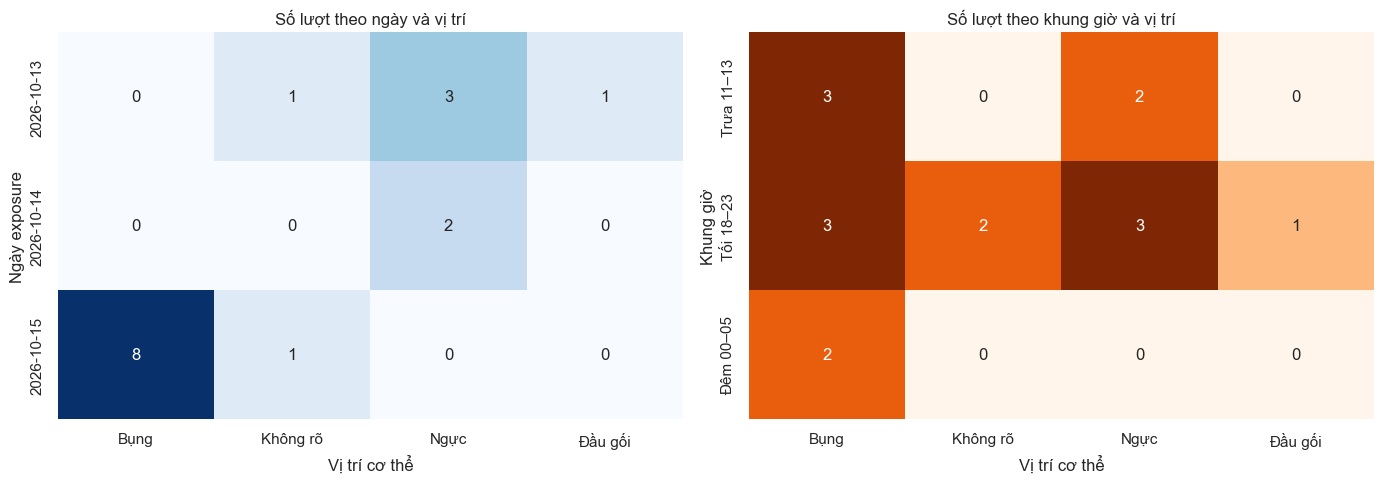

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(
    pd.crosstab(trial_manifest["exposure_started_at"].dt.date, trial_manifest["body_location"]),
    annot=True, fmt="g", cmap="Blues", ax=axes[0], cbar=False,
)
axes[0].set_title("Số lượt theo ngày và vị trí")
axes[0].set_xlabel("Vị trí cơ thể")
axes[0].set_ylabel("Ngày exposure")
sns.heatmap(
    pd.crosstab(trial_manifest["time_block"], trial_manifest["body_location"]),
    annot=True, fmt="g", cmap="Oranges", ax=axes[1], cbar=False,
)
axes[1].set_title("Số lượt theo khung giờ và vị trí")
axes[1].set_xlabel("Vị trí cơ thể")
axes[1].set_ylabel("Khung giờ")
plt.tight_layout()
plt.savefig(FIG_DIR / "design_balance.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Pha đo và hiệu năng lấy mẫu

Đánh giá số mẫu theo pha, khoảng cách giữa mẫu, vòng lặp, thời gian đọc từng sensor và độ trễ lịch.

In [9]:
phase_counts = pd.crosstab(raw_collect["folder"], raw_collect["phase"])
display(phase_counts)

timing_columns = [
    "loop_interval_s", "loop_duration_s", "schedule_lag_s",
    "bme_read_duration_s", "mq135_read_duration_s", "mq3_read_duration_s",
]
timing_stats = raw_collect[timing_columns].describe(percentiles=[0.5, 0.95, 0.99]).T
display(timing_stats)

gap_report = []
for folder, group in raw_collect.sort_values("elapsed_s").groupby("folder"):
    gaps = group["elapsed_s"].diff()
    gap_report.append({
        "folder": folder,
        "max_gap_s": gaps.max(),
        "gaps_over_2s": int(gaps.gt(2).sum()),
        "gaps_over_3s": int(gaps.gt(3).sum()),
    })
gap_report = pd.DataFrame(gap_report)
display(gap_report)

phase,BASELINE,EXPOSURE,MONITOR,RECOVERY,WAIT_EXPOSURE,WAIT_FINISH,WAIT_RECOVERY
folder,,,,,,,
Tai_bung_khongao_20261015_001113_aa68ef934bd849bb83728d3e4388793c,60,120,28,60,6,2,43
Tai_bung_khongao_20261015_112709_339b4287bbac4afb93c0f5bd6dbba08a,60,120,996,60,63,20,12
Tai_bung_khongao_20261015_213223_05f4da5dc65c4f328b8640657ac6d3a9,60,120,64,60,26,14,3
Tai_nguc_khongao_20261014_113723_11894303a1874516b6788175a0735b30,60,120,48,60,16,2,9
aDung_moitamxonggg_20261015_210313_dde7430f0ddd4a74800392704ba2e9f7,60,120,598,60,17,35,8
aMinh_bung_khongao_20261015_114954_609ad960dfe641d2ba50684fdc785f59,60,120,52,60,16,10,8
aMinh_bung_khongao_20261015_212513_200ef1f4d4d24e1f952d80e791223faa,60,120,38,60,14,3,8
aMinh_nguc_khongao_20261013_213637_e5561f0c05504090a4bd76ae0d777e82,60,120,51,60,16,3,13
aMinh_nguc_khongao_20261014_110319_b23fb89ed4854dd3b738bc020759644d,60,120,1615,60,52,6,34


,count,mean,std,min,50%,95%,99%,max
loop_interval_s,10472.0,1.000001,0.000628,0.984768,1.000000,1.000098,1.002024,1.012272
loop_duration_s,10478.0,0.254339,0.004321,0.251279,0.252030,0.263116,0.266495,0.283977
schedule_lag_s,10478.0,0.000167,0.000461,0.000022,0.000096,0.000214,0.002302,0.015330
bme_read_duration_s,10478.0,0.186891,0.002152,0.185772,0.185821,0.191759,0.192069,0.200050
mq135_read_duration_s,10478.0,0.033740,0.001318,0.032548,0.033098,0.036107,0.037771,0.051114
mq3_read_duration_s,10478.0,0.033575,0.001301,0.032469,0.032902,0.035915,0.037759,0.052095


,folder,max_gap_s,gaps_over_2s,gaps_over_3s
0,Tai_bung_khongao_20261015_001113_aa68ef934bd84...,1.010595,0,0
1,Tai_bung_khongao_20261015_112709_339b4287bbac4...,1.008790,0,0
2,Tai_bung_khongao_20261015_213223_05f4da5dc65c4...,1.004190,0,0
3,Tai_nguc_khongao_20261014_113723_11894303a1874...,1.005095,0,0
4,aDung_moitamxonggg_20261015_210313_dde7430f0dd...,1.005268,0,0
5,aMinh_bung_khongao_20261015_114954_609ad960dfe...,1.003782,0,0
6,aMinh_bung_khongao_20261015_212513_200ef1f4d4d...,1.004727,0,0
7,aMinh_nguc_khongao_20261013_213637_e5561f0c055...,1.005414,0,0
8,aMinh_nguc_khongao_20261014_110319_b23fb89ed48...,1.006921,0,0
9,aQuy_bung_khongao_20261014_235247_13c0a11091f7...,1.012272,0,0


## 8. Thống kê cảm biến trong ba pha chính

MONITOR và các pha chờ bị loại khỏi bảng chính để warm-up dài không làm sai trọng số. Mỗi collect đóng góp đúng 60/120/60 mẫu.

In [10]:
core = raw_collect.loc[raw_collect["phase"].isin(CORE_PHASES)].copy()
for column in SIGNALS + ["mq135_adc_count", "mq3_adc_count"]:
    core[column] = pd.to_numeric(core[column], errors="coerce")

global_stats = core[SIGNALS + ["mq135_adc_count", "mq3_adc_count"]].agg(
    ["count", "min", "mean", "median", "std", "max"]
).T
display(global_stats)

phase_statistics = (
    core.groupby("phase", observed=True)[SIGNALS]
    .agg(["count", "mean", "median", "std", "min", "max"])
)
display(phase_statistics)

,count,min,mean,median,std,max
temperature_c,3840.0,32.529381,34.147653,34.282598,0.547344,34.861908
humidity_pct,3840.0,54.843754,60.835793,60.060827,3.972440,68.093269
pressure_hpa,3840.0,1010.726250,1012.137748,1012.346250,1.029810,1013.580938
gas_resistance_ohm,3840.0,78769.234375,100619.163590,100431.539062,6151.529512,108681.804688
mq135_voltage_v,3840.0,0.047625,0.123433,0.111063,0.054875,0.281750
mq3_voltage_v,3840.0,0.263750,0.322596,0.307375,0.054834,0.405875
mq135_adc_count,3840.0,381.000000,987.462240,888.500000,439.000556,2254.000000
mq3_adc_count,3840.0,2110.000000,2580.765365,2459.000000,438.668523,3247.000000


temperature_c                                                       humidity_pct                                                       pressure_hpa               \
                 count       mean     median       std        min        max        count       mean     median       std        min        max        count         mean   
phase                                                                                                                                                                       
BASELINE           960  34.061343  34.109062  0.558166  32.529381  34.687096          960  60.794353  60.081572  4.087434  54.843754  68.093269          960  1012.143511   
EXPOSURE          1920  34.149405  34.282598  0.547290  32.634010  34.840218         1920  61.045973  60.371983  3.910600  55.458908  67.954529         1920  1012.135832   
RECOVERY           960  34.230460  34.417856  0.523485  32.824772  34.861908          960  60.456872  59.281929  3.953219  55.924553  67.620544          960  1012.135815   

                                                          gas_resistance_ohm                                                                         mq135_voltage_v            \
               median       std          min          max              count           mean         median          std           min            max           count      mean   
phase                                                                                                                                                                            
BASELINE  1012.354609  1.019348  1010.740625  1013.539844                960  100932.730054  101544.492188  6706.564561  78769.234375  108681.804688             960  0.122580   
EXPOSURE  1012.341797  1.030960  1010.732500  1013.580938               1920  100355.045341  100284.015625  6082.365309  81399.046875  108681.804688            1920  0.125221   
RECOVERY  1012.340703  1.038928  1010.726250  1013.563906                960  100833.833626  100313.476562  5673.843330  85561.500000  108336.859375             960  0.120709   

                                                 mq3_voltage_v                                                   
            median       std       min       max         count      mean    median       std      min       max  
phase                                                                                                            
BASELINE  0.112375  0.051366  0.051375  0.240875           960  0.322298  0.317875  0.053315  0.26450  0.405875  
EXPOSURE  0.110813  0.058367  0.047625  0.281750          1920  0.322627  0.305875  0.055258  0.26375  0.405750  
RECOVERY  0.111313  0.050838  0.051875  0.239750           960  0.322831  0.307063  0.055530  0.26475  0.405000

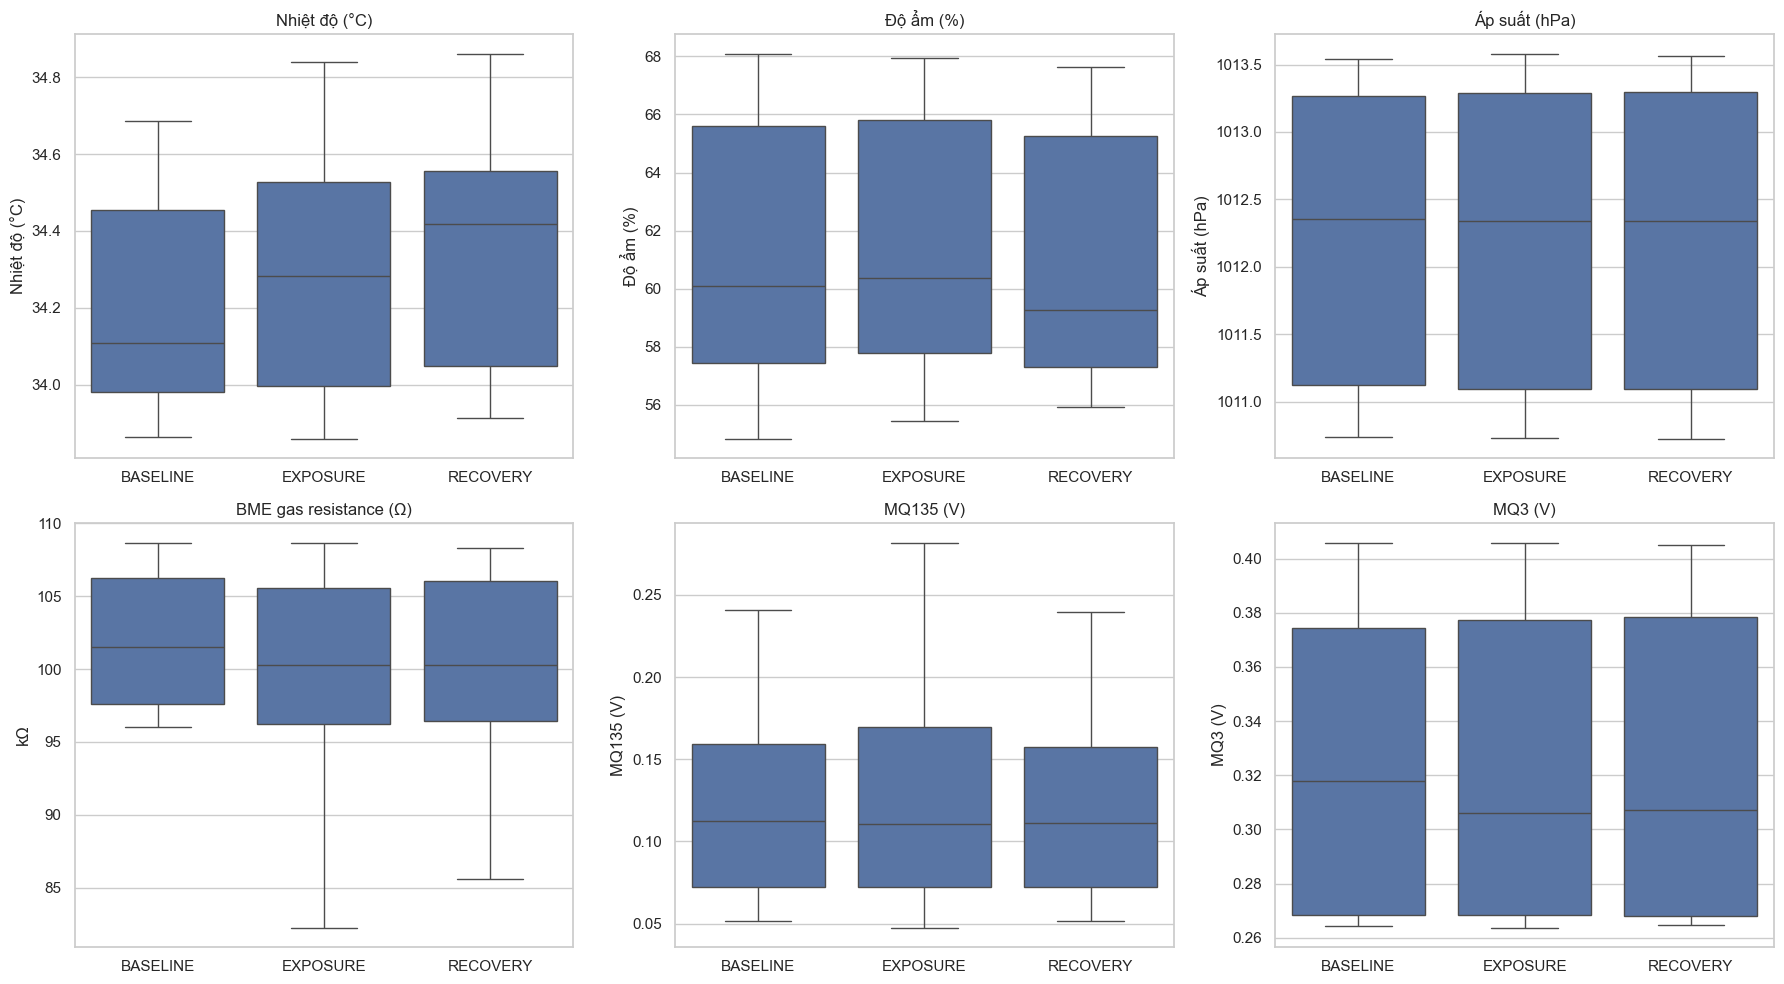

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
phase_order = ["BASELINE", "EXPOSURE", "RECOVERY"]
for ax, signal in zip(axes.flat, SIGNALS):
    plot_data = core[["phase", signal]].copy()
    if signal == "gas_resistance_ohm":
        plot_data[signal] /= 1000
        ylabel = "kΩ"
    else:
        ylabel = SIGNAL_LABELS[signal]
    sns.boxplot(data=plot_data, x="phase", y=signal, order=phase_order, ax=ax, showfliers=False)
    ax.set_title(SIGNAL_LABELS[signal])
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
plt.tight_layout()
plt.savefig(FIG_DIR / "phase_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Đặc trưng đáp ứng theo từng trial

- Nhiệt độ, độ ẩm, áp suất: dùng chênh lệch tuyệt đối exposure/recovery so với baseline.
- BME gas, MQ135, MQ3: dùng phần trăm thay đổi so với baseline.
- Tính trên trung bình pha để mỗi trial có trọng số bằng nhau.

In [12]:
response_rows = []
for folder, group in core.groupby("folder", sort=True):
    manifest = trial_manifest.loc[trial_manifest["folder"].eq(folder)].iloc[0]
    row = {
        "folder": folder,
        "run_id": manifest["run_id"],
        "date": manifest["exposure_started_at"].date(),
        "time": manifest["exposure_started_at"].strftime("%H:%M:%S"),
        "time_block": manifest["time_block"],
        "person": manifest["person"],
        "body_location": manifest["body_location"],
        "clothing": manifest["clothing"],
        "condition": manifest["condition"],
        "warning_count": manifest["warning_count"],
        "warnings": manifest["warnings"],
    }
    for signal in SIGNALS:
        means = group.groupby("phase")[signal].mean()
        base, exposure, recovery = means["BASELINE"], means["EXPOSURE"], means["RECOVERY"]
        row[f"{signal}__baseline_mean"] = base
        row[f"{signal}__exposure_mean"] = exposure
        row[f"{signal}__recovery_mean"] = recovery
        if signal in ["temperature_c", "humidity_pct", "pressure_hpa"]:
            row[f"{signal}__exposure_delta"] = exposure - base
            row[f"{signal}__recovery_delta"] = recovery - base
        else:
            row[f"{signal}__exposure_pct"] = (exposure - base) / base * 100
            row[f"{signal}__recovery_pct"] = (recovery - base) / base * 100
    response_rows.append(row)

trial_response = pd.DataFrame(response_rows).sort_values(["date", "time"])
display(trial_response)

response_summary_rows = []
for signal in SIGNALS:
    suffix = "delta" if signal in ["temperature_c", "humidity_pct", "pressure_hpa"] else "pct"
    for stage in ["exposure", "recovery"]:
        column = f"{signal}__{stage}_{suffix}"
        values = trial_response[column]
        response_summary_rows.append({
            "signal": signal,
            "stage": stage,
            "unit": "absolute" if suffix == "delta" else "% baseline",
            "mean": values.mean(),
            "median": values.median(),
            "min": values.min(),
            "max": values.max(),
            "positive_trials": int(values.gt(0).sum()),
            "n": len(values),
        })
response_summary = pd.DataFrame(response_summary_rows)
display(response_summary)

,folder,run_id,date,time,time_block,person,body_location,clothing,condition,warning_count,warnings,temperature_c__baseline_mean,temperature_c__exposure_mean,temperature_c__recovery_mean,temperature_c__exposure_delta,temperature_c__recovery_delta,humidity_pct__baseline_mean,humidity_pct__exposure_mean,humidity_pct__recovery_mean,humidity_pct__exposure_delta,humidity_pct__recovery_delta,pressure_hpa__baseline_mean,pressure_hpa__exposure_mean,pressure_hpa__recovery_mean,pressure_hpa__exposure_delta,pressure_hpa__recovery_delta,gas_resistance_ohm__baseline_mean,gas_resistance_ohm__exposure_mean,gas_resistance_ohm__recovery_mean,gas_resistance_ohm__exposure_pct,gas_resistance_ohm__recovery_pct,mq135_voltage_v__baseline_mean,mq135_voltage_v__exposure_mean,mq135_voltage_v__recovery_mean,mq135_voltage_v__exposure_pct,mq135_voltage_v__recovery_pct,mq3_voltage_v__baseline_mean,mq3_voltage_v__exposure_mean,mq3_voltage_v__recovery_mean,mq3_voltage_v__exposure_pct,mq3_voltage_v__recovery_pct
14,hihi_20261013_204946_06bec06c8e9644248819563d6...,06bec06c8e9644248819563d66f6ec6e,2026-10-13,20:55:14,Tối 18–23,Không rõ,Không rõ,Không rõ,Thử/không rõ,0,,34.071420,34.107914,34.168142,0.036494,0.096722,68.015068,67.772934,67.510833,-0.242134,-0.504235,1013.291014,1013.279212,1013.268749,-0.011803,-0.022266,80210.116146,83700.916341,86423.749089,4.352070,7.746695,0.094931,0.095040,0.095115,0.114118,0.193122,0.271090,0.270298,0.269744,-0.292031,-0.496453
13,anhdung_daugoi_20261013_210342_9df3c0be58094f2...,9df3c0be58094f2f956cf6a3d1fc0769,2026-10-13,21:24:57,Tối 18–23,Dũng,Đầu gối,Không rõ,Thông thường,0,,34.463856,34.524861,34.508485,0.061004,0.044629,66.087821,66.036598,65.941797,-0.051223,-0.146024,1013.248669,1013.275912,1013.329385,0.027243,0.080716,97765.883854,95673.247656,96923.498828,-2.140456,-0.861635,0.072208,0.072060,0.071946,-0.204847,-0.363531,0.269217,0.269081,0.268898,-0.050300,-0.118399
15,tai_nguc_coao_20261013_212913_aba9f0d8158743e7...,aba9f0d8158743e7b0c720f596b55a9b,2026-10-13,21:32:54,Tối 18–23,Tài,Ngực,Có áo,Thông thường,0,,34.429883,34.535377,34.641095,0.105494,0.211212,66.123788,66.408996,65.741418,0.285208,-0.382370,1013.397389,1013.424760,1013.458964,0.027371,0.061574,97511.439453,96351.837630,95915.922135,-1.189196,-1.636236,0.072019,0.072123,0.071998,0.144638,-0.028928,0.268248,0.268230,0.267517,-0.006601,-0.272602
7,aMinh_nguc_khongao_20261013_213637_e5561f0c055...,e5561f0c05504090a4bd76ae0d777e82,2026-10-13,21:38:44,Tối 18–23,Minh,Ngực,Không áo,Thông thường,0,,34.576667,34.709585,34.821236,0.132918,0.244569,65.780352,65.891329,65.252479,0.110977,-0.527873,1013.490480,1013.514505,1013.522905,0.024024,0.032424,96601.922786,95466.588737,95780.150781,-1.175271,-0.850679,0.072000,0.071971,0.071931,-0.040509,-0.095486,0.267296,0.267035,0.266996,-0.097426,-0.112235
12,aQuy_nguc_khongao_20261013_214446_d6c168cc5613...,d6c168cc561348d7a024b07526ca7060,2026-10-13,21:46:46,Tối 18–23,Quy,Ngực,Không áo,Thông thường,0,,34.667115,34.738396,34.788134,0.071281,0.121020,65.498671,65.736916,65.299889,0.238245,-0.198782,1013.490030,1013.509656,1013.524419,0.019626,0.034389,96737.052995,95938.612370,95908.194141,-0.825372,-0.856816,0.071954,0.071898,0.071775,-0.078175,-0.249001,0.266560,0.266694,0.266283,0.050020,-0.103948
8,aMinh_nguc_khongao_20261014_110319_b23fb89ed48...,b23fb89ed4854dd3b738bc020759644d,2026-10-14,11:32:06,Trưa 11–13,Minh,Ngực,Không áo,Thông thường,1,mq135_voltage_v: chưa hồi phục về ngưỡng nền,34.031322,34.286513,34.445174,0.255191,0.413852,60.178788,60.684436,59.971168,0.505649,-0.207620,1012.676245,1012.622191,1012.583250,-0.054054,-0.092995,106114.606120,102920.718099,101376.848828,-3.009848,-4.464755,0.143660,0.111659,0.112454,-22.275476,-21.722233,0.329731,0.303799,0.305948,-7.864675,-7.212945
3,Tai_nguc_khongao_20261014_113723_11894303a1874...,11894303a1874516b6788175a0735b30,2026-10-14,11:39:27,Trưa 11–13,Tài,Ngực,Không áo,Thông thường,0,,34.299230,34.402949,34.471279,0.103718,0.172048,60.057214,60.570529,58.9

,signal,stage,unit,mean,median,min,max,positive_trials,n
0,temperature_c,exposure,absolute,0.088062,0.086343,-0.113240,0.255191,15,16
1,temperature_c,recovery,absolute,0.169117,0.170102,-0.134927,0.413852,15,16
2,humidity_pct,exposure,absolute,0.251620,0.210369,-0.397088,0.939369,13,16
3,humidity_pct,recovery,absolute,-0.337481,-0.327651,-1.147110,1.052285,2,16
4,pressure_hpa,exposure,absolute,-0.007678,-0.011636,-0.054054,0.027371,6,16
5,pressure_hpa,recovery,absolute,-0.007695,-0.018436,-0.092995,0.080716,6,16
6,gas_resistance_ohm,exposure,% baseline,-0.512195,-0.809989,-3.009848,4.352070,3,16
7,gas_resistance_ohm,recovery,% baseline,0.006418,-0.142814,-4.464755,7.746695,5,16
8,mq135_voltage_v,exposure,% baseline,1.919567,0.597995,-22.275476,17.679923,11,16
9,mq135_voltage_v,recovery,% baseline,-1.131936,-0.172244,-21.722233,11.391080,6,16


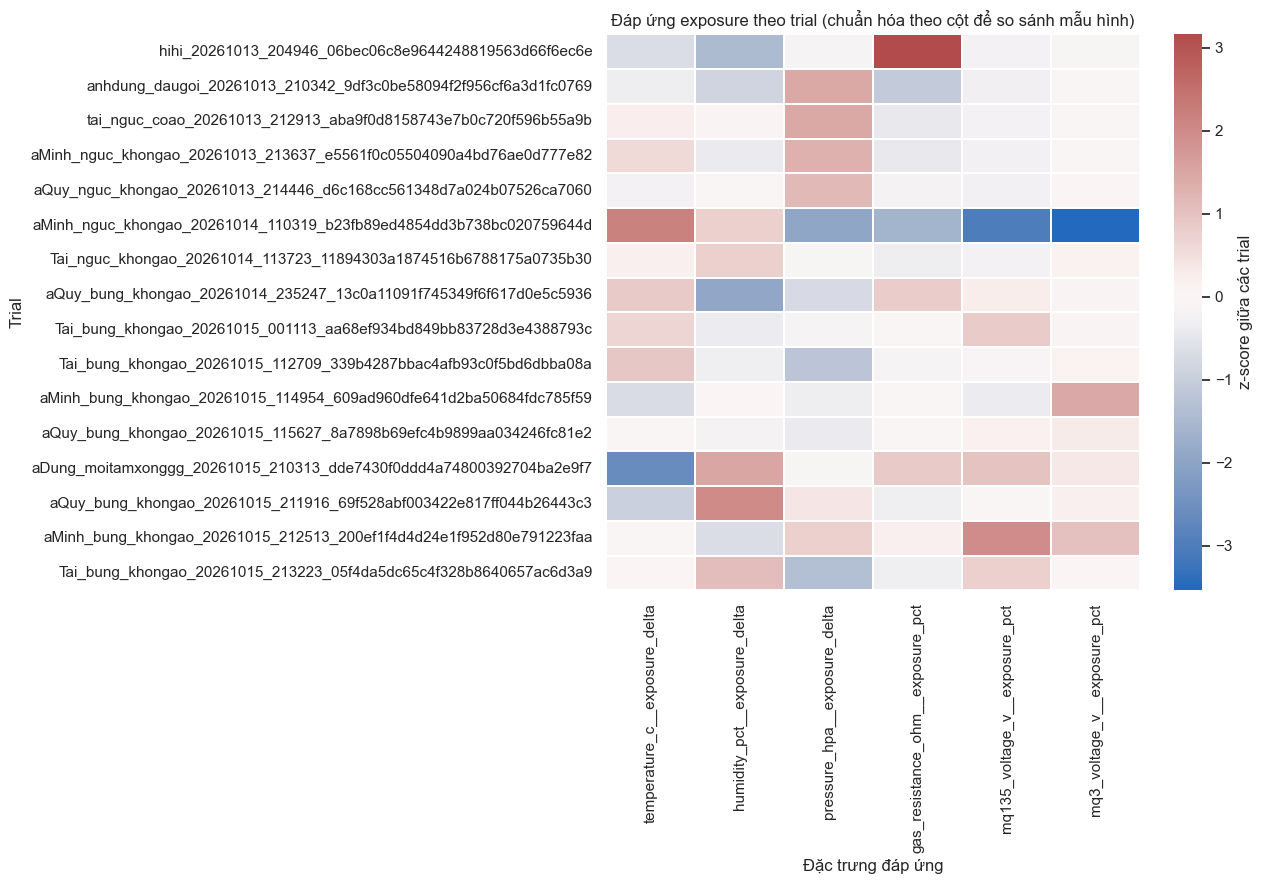

In [13]:
heat_columns = [
    "temperature_c__exposure_delta", "humidity_pct__exposure_delta", "pressure_hpa__exposure_delta",
    "gas_resistance_ohm__exposure_pct", "mq135_voltage_v__exposure_pct", "mq3_voltage_v__exposure_pct",
]
heat = trial_response.set_index("folder")[heat_columns]
heat_z = (heat - heat.mean()) / heat.std(ddof=0).replace(0, np.nan)
plt.figure(figsize=(13, 9))
sns.heatmap(heat_z, center=0, cmap="vlag", linewidths=.3, cbar_kws={"label": "z-score giữa các trial"})
plt.title("Đáp ứng exposure theo trial (chuẩn hóa theo cột để so sánh mẫu hình)")
plt.xlabel("Đặc trưng đáp ứng")
plt.ylabel("Trial")
plt.tight_layout()
plt.savefig(FIG_DIR / "response_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Drift theo ngày, người, vị trí, áo và giờ

Các bảng nhóm được tính ở cấp trial. Chúng mô tả dữ liệu hiện có, không chứng minh quan hệ nhân quả vì thiết kế không cân bằng.

In [14]:
group_rows = []
group_keys = ["date", "time_block", "person", "body_location", "clothing", "condition"]
feature_columns = [
    "temperature_c__baseline_mean", "humidity_pct__baseline_mean", "pressure_hpa__baseline_mean",
    "gas_resistance_ohm__baseline_mean", "mq135_voltage_v__baseline_mean", "mq3_voltage_v__baseline_mean",
    "temperature_c__exposure_delta", "humidity_pct__exposure_delta", "pressure_hpa__exposure_delta",
    "gas_resistance_ohm__exposure_pct", "mq135_voltage_v__exposure_pct", "mq3_voltage_v__exposure_pct",
]
for key in group_keys:
    for value, group in trial_response.groupby(key, dropna=False):
        row = {"group_type": key, "group_value": value, "n_trials": len(group)}
        row.update({column: group[column].mean() for column in feature_columns})
        group_rows.append(row)
group_statistics = pd.DataFrame(group_rows)

for key in group_keys:
    display(group_statistics.loc[group_statistics["group_type"].eq(key)])

,group_type,group_value,n_trials,temperature_c__baseline_mean,humidity_pct__baseline_mean,pressure_hpa__baseline_mean,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean,temperature_c__exposure_delta,humidity_pct__exposure_delta,pressure_hpa__exposure_delta,gas_resistance_ohm__exposure_pct,mq135_voltage_v__exposure_pct,mq3_voltage_v__exposure_pct
0,date,2026-10-13,5,34.441788,66.301140,1013.383517,93765.283047,0.076622,0.268482,0.081438,0.068215,0.017292,-0.195645,-0.012955,-0.079268
1,date,2026-10-14,2,34.165276,60.118001,1012.613378,104615.125977,0.128233,0.318521,0.179455,0.509482,-0.032762,-2.026146,-11.096646,-3.750484
2,date,2026-10-15,9,33.826888,57.885328,1011.350204,104096.334852,0.146856,0.353035,0.071432,0.296209,-0.015977,-0.351623,5.885681,0.950674


,group_type,group_value,n_trials,temperature_c__baseline_mean,humidity_pct__baseline_mean,pressure_hpa__baseline_mean,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean,temperature_c__exposure_delta,humidity_pct__exposure_delta,pressure_hpa__exposure_delta,gas_resistance_ohm__exposure_pct,mq135_voltage_v__exposure_pct,mq3_voltage_v__exposure_pct
3,time_block,Trưa 11–13,5,34.277779,58.977981,1011.614240,101563.039193,0.144256,0.339698,0.126779,0.322183,-0.027063,-1.204507,-3.790960,-0.646723
4,time_block,Tối 18–23,9,34.236282,61.779786,1012.388796,99263.625955,0.104224,0.324785,0.053519,0.299324,0.005448,-0.263315,4.104311,0.374960
5,time_block,Đêm 00–05,2,32.733028,60.900837,1012.362903,106867.925651,0.150993,0.267602,0.146709,-0.139458,-0.018284,0.098624,6.364536,0.258868


,group_type,group_value,n_trials,temperature_c__baseline_mean,humidity_pct__baseline_mean,pressure_hpa__baseline_mean,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean,temperature_c__exposure_delta,humidity_pct__exposure_delta,pressure_hpa__exposure_delta,gas_resistance_ohm__exposure_pct,mq135_voltage_v__exposure_pct,mq3_voltage_v__exposure_pct
6,person,Dũng,2,34.289937,60.549745,1012.176367,100671.811458,0.102602,0.329133,-0.026118,0.357089,0.008138,-0.663550,4.767716,0.372989
7,person,Không rõ,1,34.071420,68.015068,1013.291014,80210.116146,0.094931,0.271090,0.036494,-0.242134,-0.011803,4.352070,0.114118,-0.292031
8,person,Minh,4,34.239662,60.069076,1012.072622,102362.845540,0.124232,0.334347,0.126650,0.225159,-0.008817,-1.240029,-1.439369,-0.578209
9,person,Quy,4,33.908220,60.325157,1011.962865,102246.814583,0.130166,0.323936,0.080417,0.240755,-0.005183,-0.430619,2.178798,0.367727
10,person,Tài,5,33.947732,60.403632,1012.102095,102986.260260,0.128710,0.318855,0.119291,0.338045,-0.014265,-0.907500,3.621160,0.209348


,group_type,group_value,n_trials,temperature_c__baseline_mean,humidity_pct__baseline_mean,pressure_hpa__baseline_mean,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean,temperature_c__exposure_delta,humidity_pct__exposure_delta,pressure_hpa__exposure_delta,gas_resistance_ohm__exposure_pct,mq135_voltage_v__exposure_pct,mq3_voltage_v__exposure_pct
11,body_location,Bụng,8,33.790747,58.244535,1011.380971,104161.159326,0.148588,0.348533,0.094516,0.237560,-0.016603,-0.497245,5.403857,0.969974
12,body_location,Không rõ,2,34.093719,61.513369,1012.197540,91893.927604,0.113964,0.330070,-0.038373,0.261634,-0.011385,2.582713,4.927199,0.252123
13,body_location,Ngực,5,34.400843,63.527763,1013.120931,100016.133438,0.094488,0.287829,0.133720,0.330679,0.001100,-1.448426,-4.433468,-1.510995
14,body_location,Đầu gối,1,34.463856,66.087821,1013.248669,97765.883854,0.072208,0.269217,0.061004,-0.051223,0.027243,-2.140456,-0.204847,-0.050300


,group_type,group_value,n_trials,temperature_c__baseline_mean,humidity_pct__baseline_mean,pressure_hpa__baseline_mean,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean,temperature_c__exposure_delta,humidity_pct__exposure_delta,pressure_hpa__exposure_delta,gas_resistance_ohm__exposure_pct,mq135_voltage_v__exposure_pct,mq3_voltage_v__exposure_pct
15,clothing,Có áo,1,34.429883,66.123788,1013.397389,97511.439453,0.072019,0.268248,0.105494,0.285208,0.027371,-1.189196,0.144638,-0.006601
16,clothing,Không rõ,3,34.217098,63.038186,1012.547916,93851.246354,0.100045,0.309785,-0.005247,0.157348,0.001491,1.008323,3.216517,0.151315
17,clothing,Không áo,12,33.991693,59.789275,1011.937919,102988.208529,0.132427,0.329930,0.109936,0.272389,-0.012891,-0.835908,1.743240,0.017618


,group_type,group_value,n_trials,temperature_c__baseline_mean,humidity_pct__baseline_mean,pressure_hpa__baseline_mean,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean,temperature_c__exposure_delta,humidity_pct__exposure_delta,pressure_hpa__exposure_delta,gas_resistance_ohm__exposure_pct,mq135_voltage_v__exposure_pct,mq3_voltage_v__exposure_pct
18,condition,Sau tắm,1,34.116017,55.011670,1011.104065,103577.739062,0.132996,0.389050,-0.113240,0.765401,-0.010967,0.813357,9.740280,0.796277
19,condition,Thông thường,14,34.056718,60.691637,1012.135792,102223.987547,0.123811,0.321188,0.106124,0.250190,-0.007149,-0.954325,1.489905,0.011037
20,condition,Thử/không rõ,1,34.071420,68.015068,1013.291014,80210.116146,0.094931,0.271090,0.036494,-0.242134,-0.011803,4.352070,0.114118,-0.292031


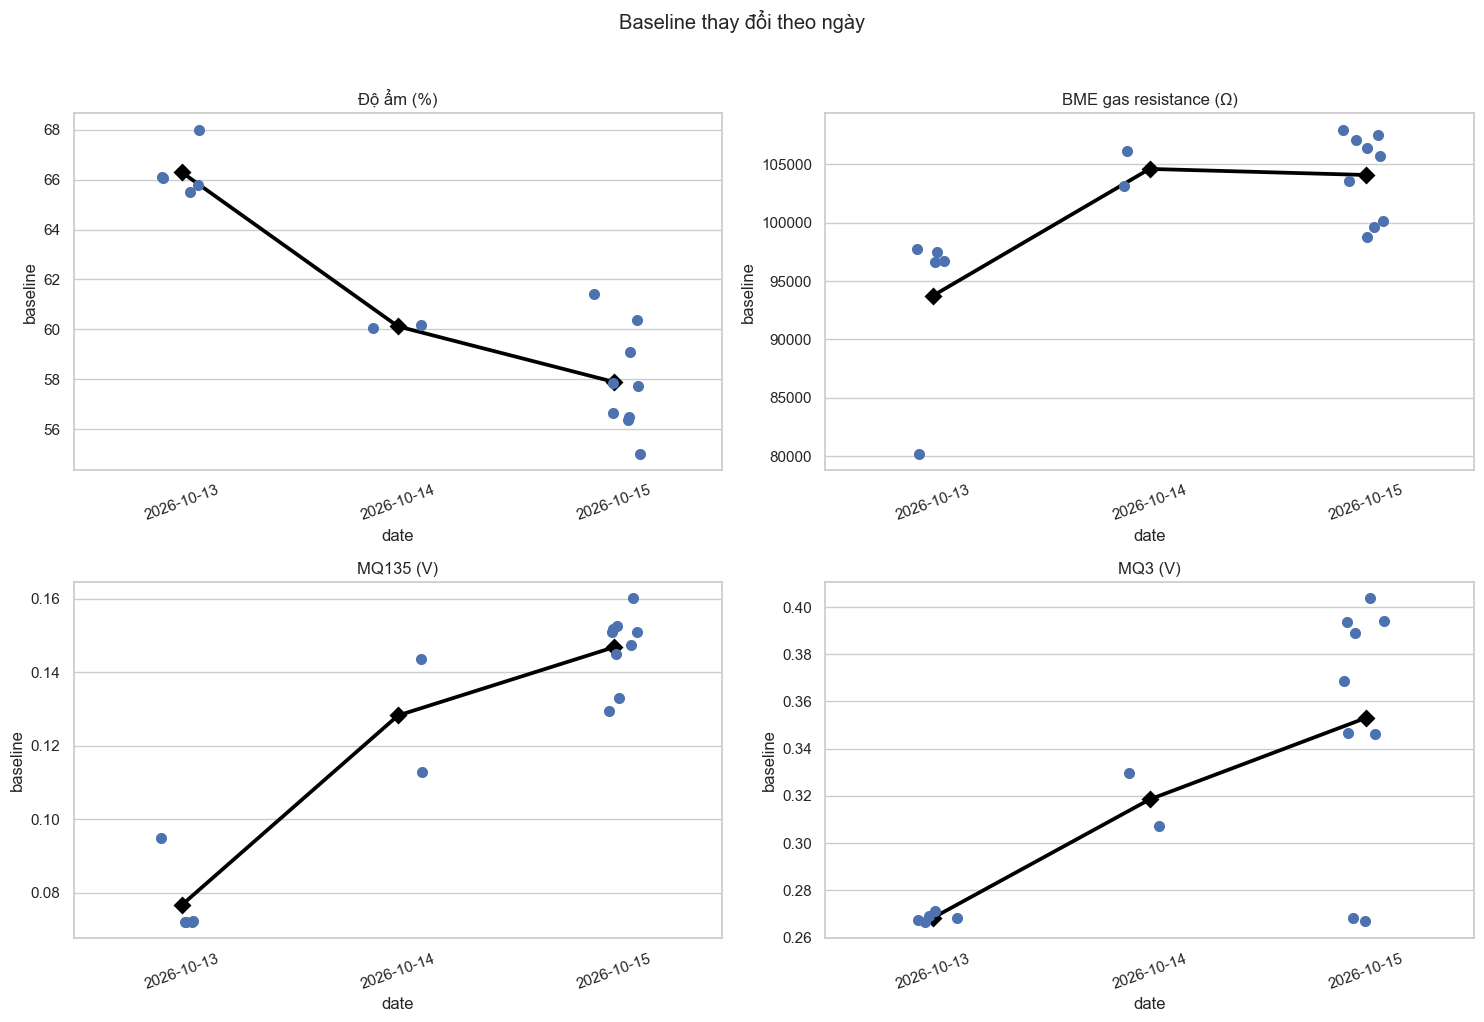

In [15]:
baseline_cols = [
    "humidity_pct__baseline_mean", "gas_resistance_ohm__baseline_mean",
    "mq135_voltage_v__baseline_mean", "mq3_voltage_v__baseline_mean",
]
baseline_long = trial_response.melt(
    id_vars=["date", "folder"], value_vars=baseline_cols,
    var_name="signal", value_name="baseline",
)
baseline_long["signal"] = baseline_long["signal"].str.replace("__baseline_mean", "", regex=False)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, signal in zip(axes.flat, baseline_long["signal"].unique()):
    sub = baseline_long.loc[baseline_long["signal"].eq(signal)]
    sns.stripplot(data=sub, x="date", y="baseline", jitter=.12, size=8, ax=ax)
    sns.pointplot(data=sub, x="date", y="baseline", errorbar=None, color="black", markers="D", ax=ax)
    ax.set_title(SIGNAL_LABELS.get(signal, signal))
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("Baseline thay đổi theo ngày", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_by_day.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Tương quan và confounding

Ma trận này dùng 16 trial, chỉ mang tính thăm dò. Tương quan mạnh có thể do ngày/giờ/vị trí bị gắn với nhau chứ không phải quan hệ sinh học trực tiếp.

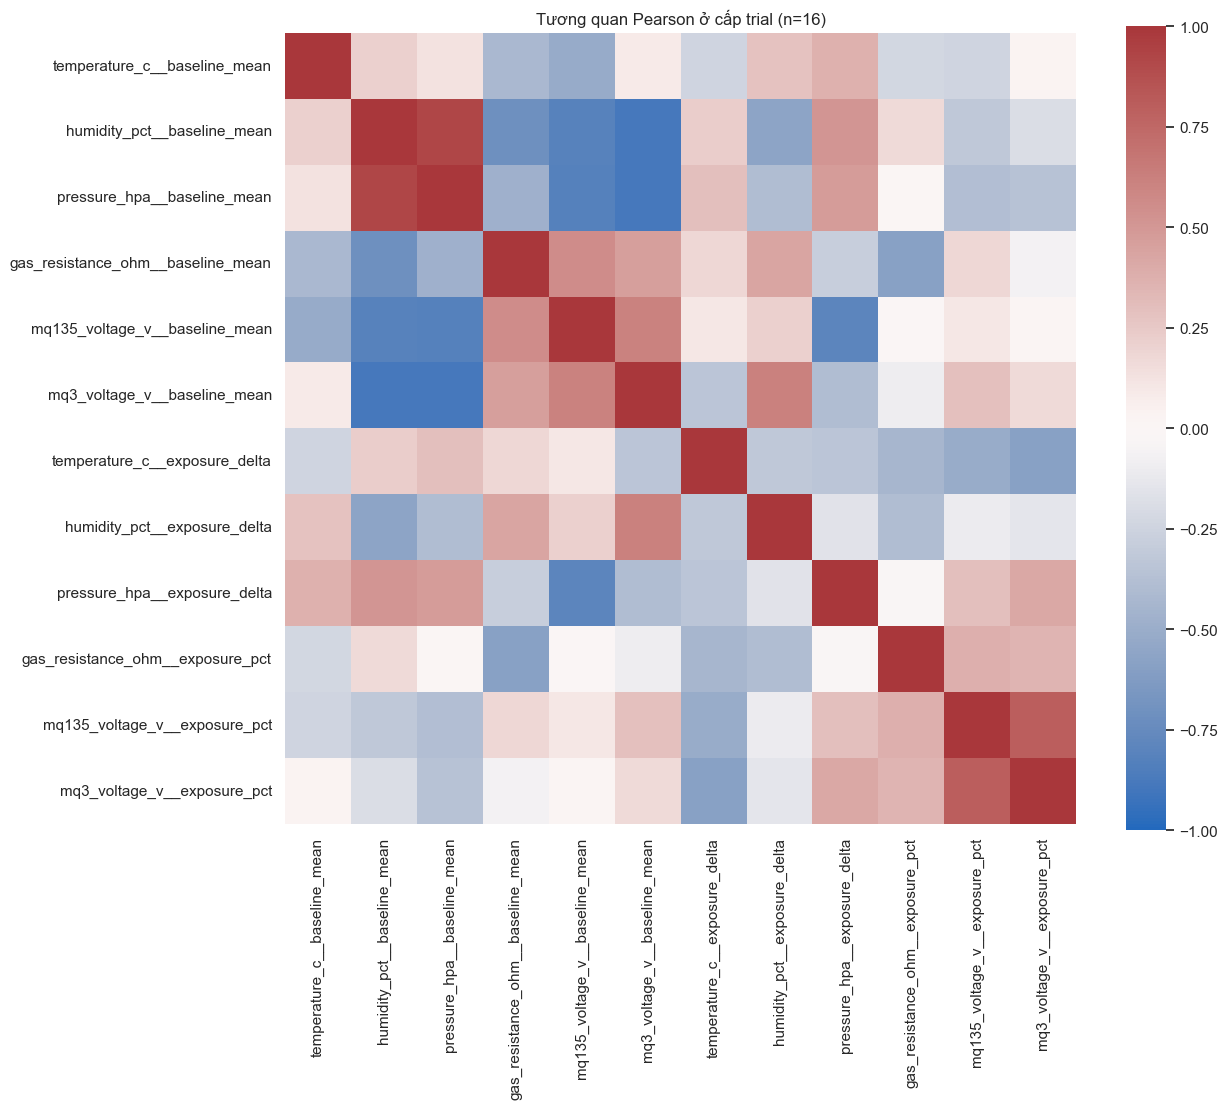

,gas_resistance_ohm__baseline_mean,mq135_voltage_v__baseline_mean,mq3_voltage_v__baseline_mean
humidity_pct__baseline_mean,-0.718628,-0.812987,-0.886798
temperature_c__baseline_mean,-0.428721,-0.519236,0.093553


In [16]:
corr_features = feature_columns
corr = trial_response[corr_features].corr(method="pearson")
plt.figure(figsize=(13, 11))
sns.heatmap(corr, center=0, cmap="vlag", vmin=-1, vmax=1, square=True)
plt.title("Tương quan Pearson ở cấp trial (n=16)")
plt.tight_layout()
plt.savefig(FIG_DIR / "trial_correlations.png", dpi=160, bbox_inches="tight")
plt.show()

selected_corr = corr.loc[
    ["humidity_pct__baseline_mean", "temperature_c__baseline_mean"],
    ["gas_resistance_ohm__baseline_mean", "mq135_voltage_v__baseline_mean", "mq3_voltage_v__baseline_mean"],
]
display(selected_corr)

## 12. Cảnh báo và tiêu chí chất lượng

Tổng hợp warning từ `summary.json`, kiểm tra pre-baseline elapsed bất nhất và tạo cờ QC cho mỗi collect.

In [17]:
quality_rows = []
for _, run in collects.iterrows():
    group = raw_collect.loc[raw_collect["folder"].eq(run["folder"])].sort_values("elapsed_s")
    core_group = group.loc[group["phase"].isin(CORE_PHASES)]
    max_gap = group["elapsed_s"].diff().max()
    core_valid = (
        core_group["bme_status"].eq("OK") &
        core_group["mq135_status"].eq("OK") &
        core_group["mq3_status"].eq("OK") &
        core_group["gas_valid"].astype(str).eq("True") &
        core_group["heater_stable"].astype(str).eq("True")
    )
    warnings = run["warnings"] or ""
    pre_eval = run["prebaseline_evaluated_at_s"]
    elapsed = run["elapsed_s"]
    quality_rows.append({
        "folder": run["folder"],
        "complete": run["status"] == "COMPLETE",
        "core_rows": len(core_group),
        "core_valid_pct": core_valid.mean() * 100,
        "max_gap_s": max_gap,
        "adc_near_limit": bool((core_group[["mq135_adc_count", "mq3_adc_count"]].abs() >= 32700).any().any()),
        "mq135_baseline_drift_warning": "baseline drift" in warnings,
        "mq135_not_recovered_warning": "chưa hồi phục" in warnings,
        "baseline_started_without_stability": bool(run["baseline_started_without_stability"]),
        "prebaseline_elapsed_inconsistent": pd.notna(pre_eval) and pd.notna(elapsed) and pre_eval > elapsed,
        "warnings": warnings,
    })
quality_flags = pd.DataFrame(quality_rows)
display(quality_flags)
display(quality_flags.drop(columns=["folder", "warnings"]).sum(numeric_only=True).rename("count_or_sum").to_frame())

warnings_by_date = trial_response.assign(has_warning=trial_response["warning_count"].gt(0)).groupby("date").agg(
    trials=("folder", "count"), warned_trials=("has_warning", "sum")
)
display(warnings_by_date)

,folder,complete,core_rows,core_valid_pct,max_gap_s,adc_near_limit,mq135_baseline_drift_warning,mq135_not_recovered_warning,baseline_started_without_stability,prebaseline_elapsed_inconsistent,warnings
0,aMinh_nguc_khongao_20261013_213637_e5561f0c055...,True,240,100.0,1.005414,False,False,False,False,True,
1,anhdung_daugoi_20261013_210342_9df3c0be58094f2...,True,240,100.0,1.009555,False,False,False,False,False,
2,aQuy_nguc_khongao_20261013_214446_d6c168cc5613...,True,240,100.0,1.003819,False,False,False,False,True,
3,hihi_20261013_204946_06bec06c8e9644248819563d6...,True,240,100.0,1.005133,False,False,False,False,False,
4,tai_nguc_coao_20261013_212913_aba9f0d8158743e7...,True,240,100.0,1.004890,False,False,False,False,True,
5,aMinh_nguc_khongao_20261014_110319_b23fb89ed48...,True,240,100.0,1.006921,False,False,True,False,False,mq135_voltage_v: chưa hồi phục về ngưỡng nền
6,aQuy_bung_khongao_20261014_235247_13c0a11091f7...,True,240,100.0,1.012272,False,True,True,False,False,mq135_voltage_v: baseline drift vượt ngưỡng | ...
7,Tai_nguc_khongao_20261014_113723_11894303a1874...,True,240,100.0,1.005095,False,False,False,False,True,
8,aDung_moitamxonggg_20261015_210313_dde7430f0dd...,True,240,100.0,1.005268,False,True,True,False,False,mq135_voltage_v: baseline drift vượt ngưỡng | ...
9,aMinh_bung_khongao_20261015_114954_609ad960dfe...,True,240,100.0,1.003782,False,True,True,False,True,mq135_voltage_v: baseline drift vượt ngưỡng | ...


,count_or_sum
complete,16.000000
core_rows,3840.000000
core_valid_pct,1600.000000
max_gap_s,16.099501
adc_near_limit,0.000000
mq135_baseline_drift_warning,8.000000
mq135_not_recovered_warning,10.000000
baseline_started_without_stability,1.000000
prebaseline_elapsed_inconsistent,10.000000


,trials,warned_trials
date,,
2026-10-13,5,0
2026-10-14,2,1
2026-10-15,9,9


## 13. Quan sát tín hiệu theo thời gian

Các đường được đổi về phần trăm so với trung bình baseline của chính trial. Nhiệt độ/độ ẩm giữ chênh lệch tuyệt đối để tránh cách diễn giải phần trăm khó hiểu.

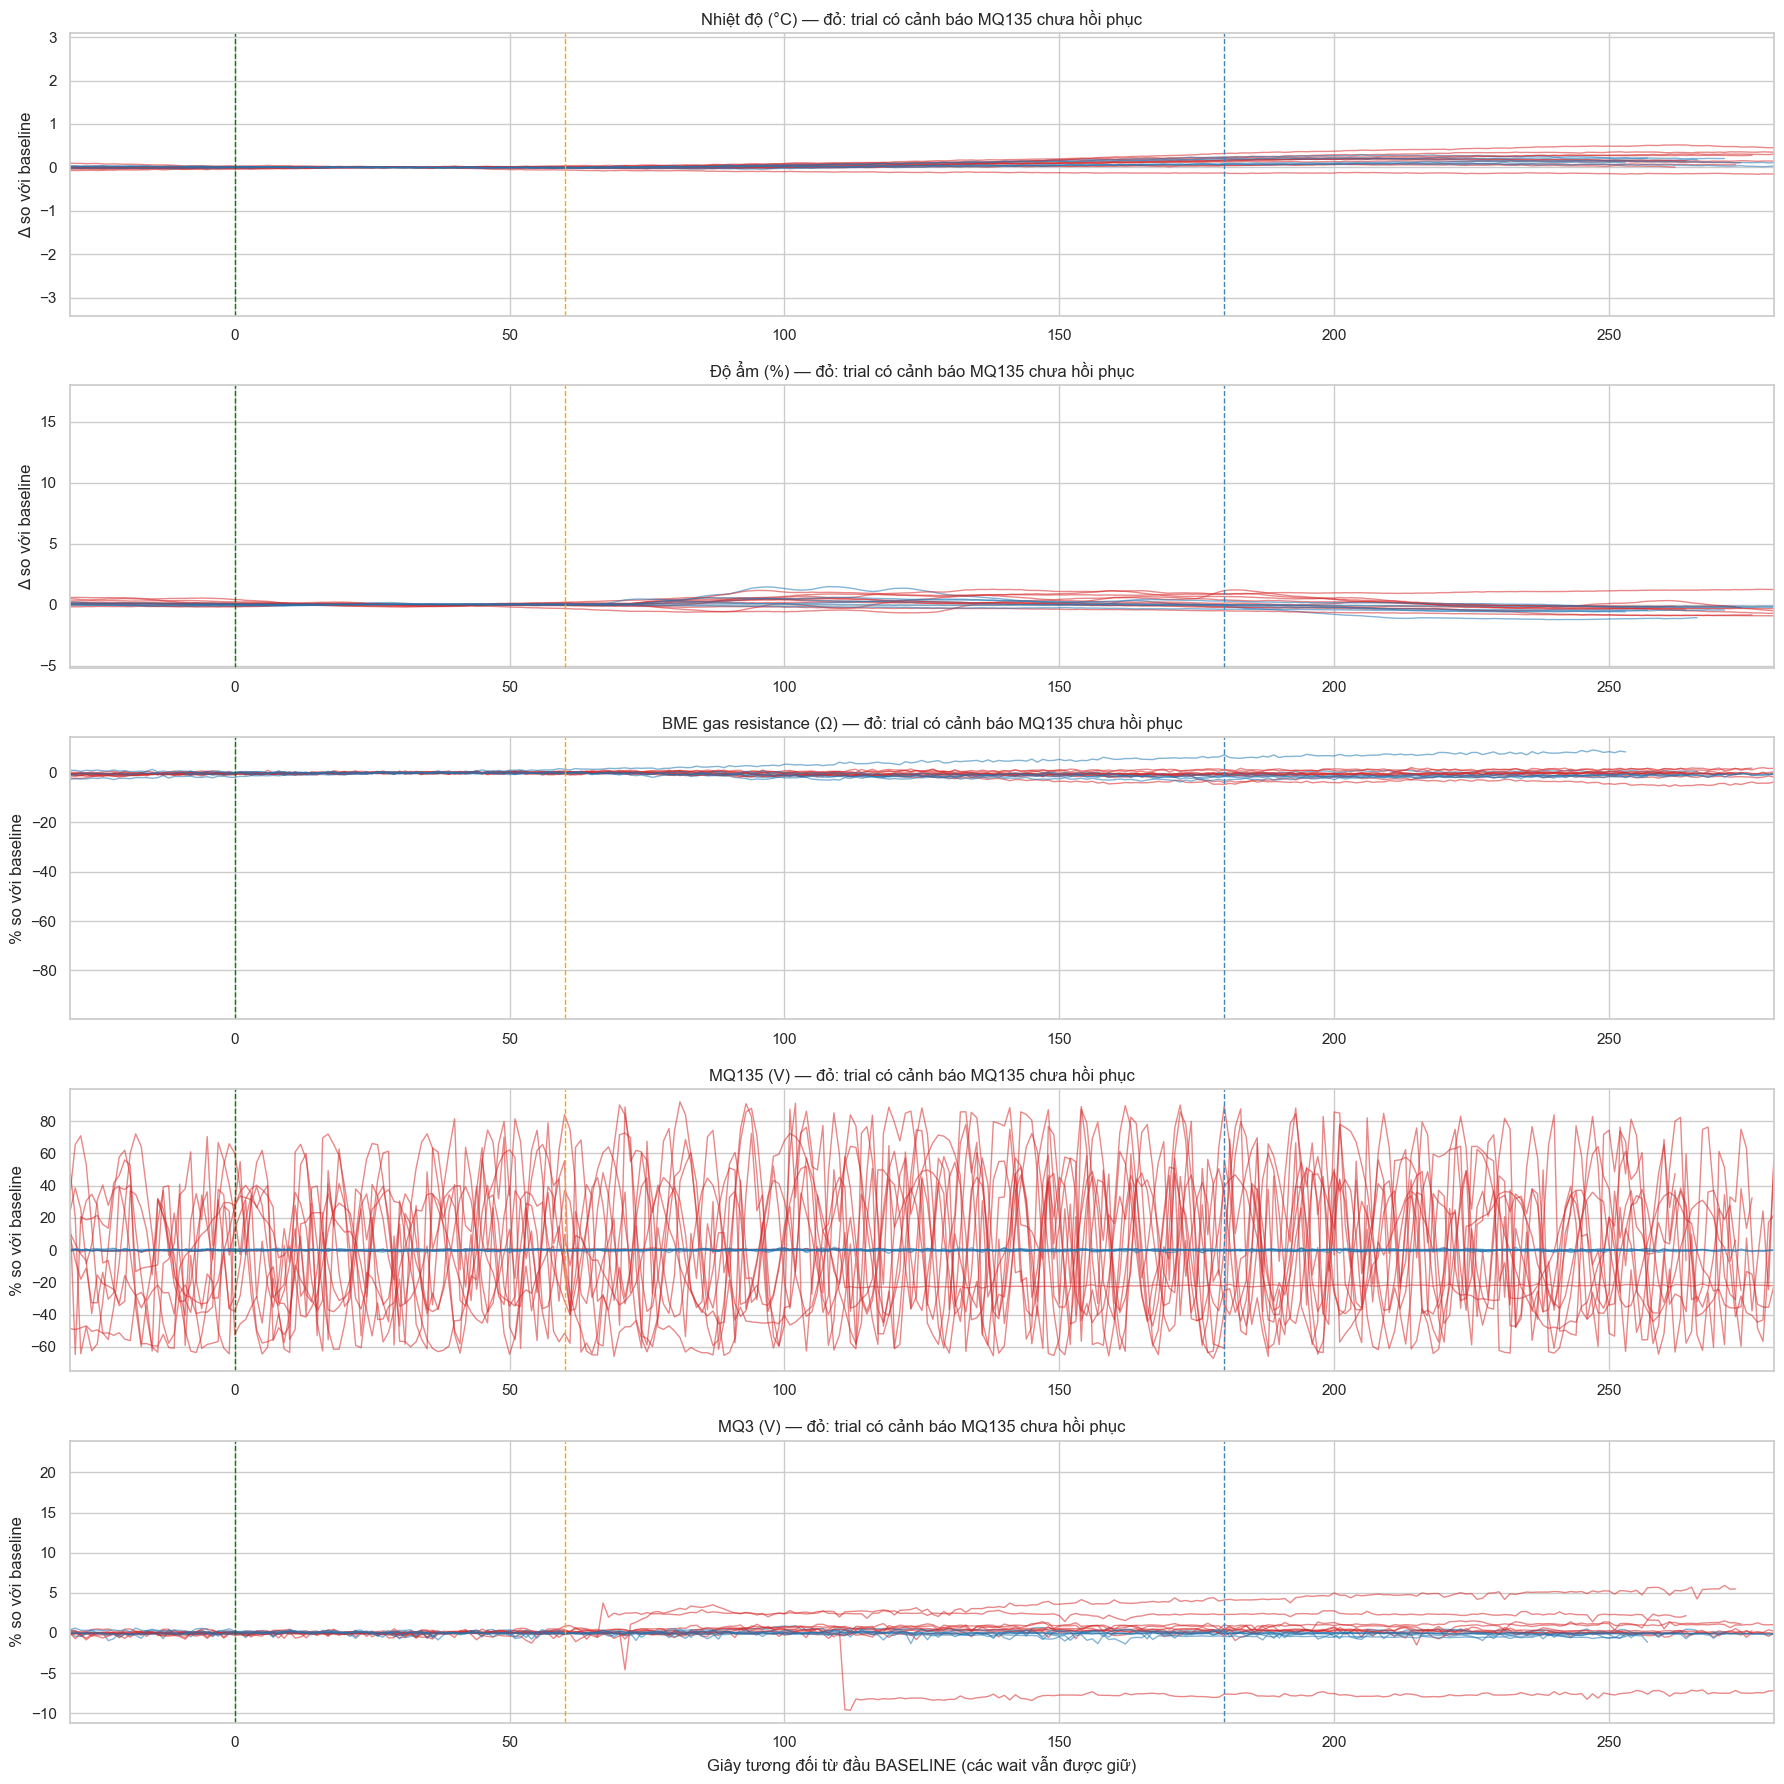

In [18]:
plot_signals = ["temperature_c", "humidity_pct", "gas_resistance_ohm", "mq135_voltage_v", "mq3_voltage_v"]
fig, axes = plt.subplots(len(plot_signals), 1, figsize=(18, 18), sharex=False)

for ax, signal in zip(axes, plot_signals):
    for folder, group in raw_collect.groupby("folder"):
        group = group.sort_values("elapsed_s")
        baseline = group.loc[group["phase"].eq("BASELINE"), signal].mean()
        x0 = group.loc[group["phase"].eq("BASELINE"), "elapsed_s"].min()
        x = group["elapsed_s"] - x0
        if signal in ["temperature_c", "humidity_pct"]:
            y = group[signal] - baseline
            ylabel = "Δ so với baseline"
        else:
            y = (group[signal] - baseline) / baseline * 100
            ylabel = "% so với baseline"
        warned = bool(quality_flags.loc[quality_flags["folder"].eq(folder), "mq135_not_recovered_warning"].iloc[0])
        ax.plot(x, y, alpha=.55, lw=1, color="tab:red" if warned else "tab:blue")
    ax.axvline(0, color="green", ls="--", lw=1)
    ax.axvline(60, color="orange", ls="--", lw=1)
    ax.axvline(180, color="steelblue", ls="--", lw=1)
    ax.set_title(SIGNAL_LABELS[signal] + " — đỏ: trial có cảnh báo MQ135 chưa hồi phục")
    ax.set_ylabel(ylabel)
    ax.set_xlim(-30, 280)
axes[-1].set_xlabel("Giây tương đối từ đầu BASELINE (các wait vẫn được giữ)")
plt.tight_layout()
plt.savefig(FIG_DIR / "aligned_signal_traces.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Phương án thu dữ liệu mới

### Thiết kế tối thiểu cân bằng

- 4 người × 2 vị trí (ngực/bụng) × 2 trạng thái áo × 5 lần lặp = **80 trial chính**.
- Thu trên ít nhất 5 ngày; mỗi ngày phải có đủ các lớp thay vì tách ngực và bụng sang ngày khác.
- Thêm blank đầu/cuối session và sau mỗi 3–4 trial: khoảng 20–30 control.
- Đầu gối và sau tắm là thí nghiệm riêng, không trộn vào nhãn chính.

### Quy trình một trial

1. Burn-in tối thiểu 30 phút.
2. Purge ≥180 giây và chờ toàn bộ BME gas/MQ135/MQ3 ổn định.
3. Baseline 120 giây.
4. Chuyển mẫu trong thời gian cố định, đề xuất 10 giây.
5. Exposure 120 giây.
6. Recovery ≥180 giây, tối đa 600 giây.
7. Chỉ chạy trial tiếp theo khi cả ba tín hiệu khí nằm trong ±5% baseline liên tục 60 giây.

### QC đề xuất trước exposure

- ≥95% mẫu hợp lệ; không gap >2 giây; không ADC saturation.
- Gas/MQ135/MQ3: |slope| <2%/phút và range <3% trong cửa sổ 60 giây.
- Nhiệt độ: |slope| <0,1°C/phút, range <0,2°C.
- Độ ẩm: |slope| <0,5 điểm %/phút, range <1 điểm %.
- Nếu không đạt thì không bắt đầu exposure và ghi lý do.

### Metadata bắt buộc bổ sung

`subject_id`, `room_id`, `body_location`, `clothing_state`, `clothing_material`, `shower_state`, `minutes_since_shower`, `minutes_since_exercise`, `distance_cm`, `chamber_volume_ml`, `pump_flow_lpm`, `ambient_temperature_c`, `ambient_humidity_pct`, `sample_order`, `operator`, `quality_status`, `quality_reasons`, `notes`.

In [19]:
design = pd.DataFrame({
    "factor": ["Người", "Vị trí", "Áo", "Lặp/tổ hợp"],
    "levels": [4, 2, 2, 5],
})
main_trials = int(design["levels"].prod())
controls = math.ceil(main_trials / 4) + 10
display(design)
print(f"Trial chính tối thiểu: {main_trials}")
print(f"Control đề xuất: khoảng {controls}")
print(f"Tổng kế hoạch: khoảng {main_trials + controls} lượt")

,factor,levels
0,Người,4
1,Vị trí,2
2,Áo,2
3,Lặp/tổ hợp,5


Trial chính tối thiểu: 80
Control đề xuất: khoảng 30
Tổng kế hoạch: khoảng 110 lượt


## 15. Xuất kết quả

Các file CSV dùng UTF-8 BOM (`utf-8-sig`) để mở đúng tiếng Việt trong Excel trên Windows.

In [20]:
exports = {
    "run_inventory.csv": runs,
    "integrity_report.csv": integrity,
    "raw_field_dictionary.csv": field_dictionary,
    "raw_field_quality.csv": field_quality,
    "duplicate_report.csv": duplicate_report,
    "trial_manifest_inferred.csv": trial_manifest,
    "phase_counts.csv": phase_counts.reset_index(),
    "timing_statistics.csv": timing_stats.reset_index(names="field"),
    "phase_statistics.csv": phase_statistics.reset_index(),
    "trial_response_features.csv": trial_response,
    "response_summary.csv": response_summary,
    "group_statistics.csv": group_statistics,
    "quality_flags.csv": quality_flags,
}
for filename, frame in exports.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")

summary_payload = {
    "dataset_root": str(DATA_ROOT),
    "runs": int(len(runs)),
    "collect_trials": int(len(collects)),
    "sessions": int(len(sessions)),
    "collect_rows": int(len(raw_collect)),
    "core_rows": int(len(core)),
    "all_collect_rows_repeated_in_sessions": bool(duplicate_report["repeated_pct"].eq(100).all()),
    "warning_trials": int(quality_flags["mq135_not_recovered_warning"].sum()),
    "mq135_baseline_drift_trials": int(quality_flags["mq135_baseline_drift_warning"].sum()),
    "prebaseline_elapsed_inconsistent_trials": int(quality_flags["prebaseline_elapsed_inconsistent"].sum()),
    "main_recommended_trials": main_trials,
    "recommended_controls_approx": controls,
}
(OUTPUT_DIR / "analysis_summary.json").write_text(
    json.dumps(summary_payload, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("Đã xuất:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(DATA_ROOT))
display(summary_payload)

Đã xuất:
 - analysis_outputs\analysis_summary.json
 - analysis_outputs\duplicate_report.csv
 - analysis_outputs\figures\aligned_signal_traces.png
 - analysis_outputs\figures\baseline_by_day.png
 - analysis_outputs\figures\design_balance.png
 - analysis_outputs\figures\phase_distributions.png
 - analysis_outputs\figures\response_heatmap.png
 - analysis_outputs\figures\trial_correlations.png
 - analysis_outputs\group_statistics.csv
 - analysis_outputs\integrity_report.csv
 - analysis_outputs\phase_counts.csv
 - analysis_outputs\phase_statistics.csv
 - analysis_outputs\quality_flags.csv
 - analysis_outputs\raw_field_dictionary.csv
 - analysis_outputs\raw_field_quality.csv
 - analysis_outputs\response_summary.csv
 - analysis_outputs\run_inventory.csv
 - analysis_outputs\timing_statistics.csv
 - analysis_outputs\trial_manifest_inferred.csv
 - analysis_outputs\trial_response_features.csv


{'dataset_root': 'D:\\PBL6\\data\\chua_co_loc_khi_van_3_c',
 'runs': 22,
 'collect_trials': 16,
 'sessions': 6,
 'collect_rows': 10478,
 'core_rows': 3840,
 'all_collect_rows_repeated_in_sessions': True,
 'warning_trials': 10,
 'mq135_baseline_drift_trials': 8,
 'prebaseline_elapsed_inconsistent_trials': 10,
 'main_recommended_trials': 80,
 'recommended_controls_approx': 30}

## 16. Kết luận sử dụng dữ liệu

- Cấu trúc file và lịch lấy mẫu tốt.
- `collect` là đơn vị dữ liệu có nhãn; `session` là log tổng chứa bản sao.
- Dữ liệu hiện tại có 16 trial độc lập, không phải 10.478 mẫu độc lập.
- MQ135 không ổn định ở phần lớn lượt ngày 14–15/10.
- Ngày, giờ, độ ẩm và vị trí bị confound; không thể gán chênh lệch hiện có cho vị trí cơ thể.
- Chỉ có một lượt có áo nên chưa đánh giá được ảnh hưởng của áo.
- Chưa có hiệu chuẩn cầu chia/ppm, phản hồi bơm, lưu lượng, khoảng cách và môi trường phòng.
- Dữ liệu phù hợp cho audit/pilot; cần thu lại theo thiết kế cân bằng trước khi làm mô hình.